In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


**Preparing the dataset**


**Use only the following columns:**

'engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg'

In [4]:
model = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']

In [5]:
df_1 = df[model]

In [6]:
df_1.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


**EDA**

Look at the fuel_efficiency_mpg variable. Does it have a long tail?

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

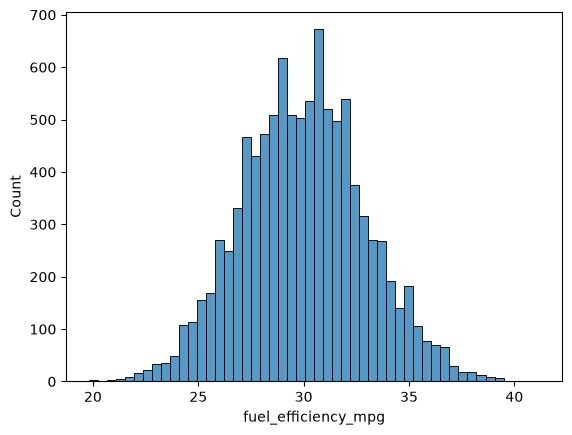

In [8]:
sns.histplot(df_1.fuel_efficiency_mpg, bins=50)

I see two long tails, so I can say it has long tail

**Question 1**

There's one column with missing values. What is it?

'engine_displacement'
'horsepower'
'vehicle_weight'
'model_year'

In [9]:
df_1.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

Horsepower is the collumn with missing values.

**Question 2**

What's the median (50% percentile) for variable 'horsepower'?

In [10]:
df_1.median()

engine_displacement    2270.0
horsepower              254.0
vehicle_weight         4280.0
model_year             2000.0
fuel_efficiency_mpg      30.0
dtype: float64

Answer: The median for horsepower is 254.0

**Prepare and split the dataset**

Shuffle the filtered dataset and create the split exactly as in the lecture:

In [11]:
import numpy as np

In [12]:
n = len(df_1)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [13]:
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

In [14]:
df_train = df_1.iloc[idx[:n_train]]
df_val = df_1.iloc[idx[n_train:n_train + n_val]]
df_test = df_1.iloc[idx[n_train + n_val:]]

For Q5, repeat the same block with each listed seed. For Q6, use seed 9.

**Question 3**

* We need to deal with missing values for the column from Q1.
* We have two options: fill it with 0 or with the mean of this variable.
* Try both options. For each, train a linear regression model without regularization using the code from the lessons.
* For computing the mean, use the training only!
* Use the validation dataset to evaluate the models and compare the RMSE of each option.
* Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.


Which option gives better RMSE?

Options:

* With 0
* With mean
* Both are equally good


#### Utilities



save the columns with Y's, fuel_efficiency_mpg

In [16]:
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

remove the columns that contains the y's

In [17]:
#
y_train

array([3.51154544, 3.40452517, 3.55820113, ..., 3.35689712, 3.48431229,
       3.36729583], shape=(6000,))

In [18]:
#
df_train

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
6252,1900,239.0,3790,2015,32.5
4684,2000,224.0,4380,1992,29.1
1731,2330,286.0,4090,2022,34.1
4742,2300,NaN,4150,1997,30.6
4521,2340,269.0,4400,2001,30.7
...,...,...,...,...,...
7895,2280,242.0,4590,2018,29.8
9590,2300,NaN,4240,1984,25.1
7288,2240,255.0,4190,1989,27.7
278,2430,254.0,4280,2020,31.6


In [19]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [20]:
#
df_train

,engine_displacement,horsepower,vehicle_weight,model_year
6252,1900,239.0,3790,2015
4684,2000,224.0,4380,1992
1731,2330,286.0,4090,2022
4742,2300,NaN,4150,1997
4521,2340,269.0,4400,2001
...,...,...,...,...
7895,2280,242.0,4590,2018
9590,2300,NaN,4240,1984
7288,2240,255.0,4190,1989
278,2430,254.0,4280,2020


Linear regresation function:

In [21]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

Root mean square error function:

In [22]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

#### filling the gaps using 0s

In [23]:
def prepare_X(df):
    df = df.copy()
    
    #df['age'] = 2017 - df['year']
    #features = base + ['age']
    
    #df_num = df[features]
    df_num = df.fillna(0)
    X = df_num.values

    return X

In [24]:
X_train = prepare_X(df_train)
X_train

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]], shape=(6000, 4))

* Train a linear regression model without regularization using the code from the lessons.

In [25]:
#X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)


In [32]:
#
y_pred = w0 + X_train.dot(w)
#y_pred = np.expm1(y_pred)
y_pred

array([3.56241747, 3.40471979, 3.52582873, ..., 3.40758805, 3.48954957,
       3.41959848], shape=(6000,))

In [33]:
#root square mean error
rmse(y_train, y_pred)

np.float64(0.07127079986896064)

<Axes: ylabel='Count'>

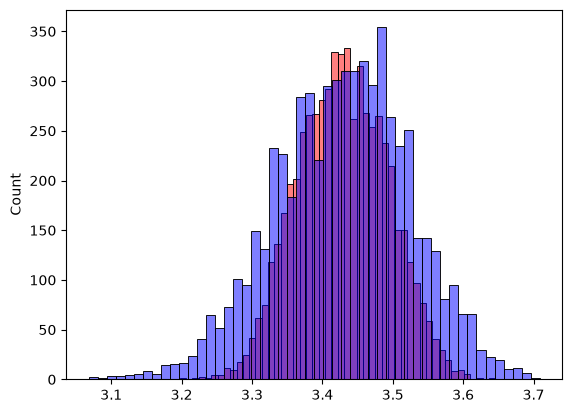

In [34]:
#
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

**Results**

Filling values nan with zeros is not that bad.

#### Filling th gaps using mean

In [35]:
df_train = df_1.iloc[idx[:n_train]]
df_val = df_1.iloc[idx[n_train:n_train + n_val]]
df_test = df_1.iloc[idx[n_train + n_val:]]

In [36]:
#mean
feature_mean = df_train["fuel_efficiency_mpg"].mean()

In [37]:
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

In [38]:
def prepare_X(df):
    df = df.copy()
    
    #df['age'] = 2017 - df['year']
    #features = base + ['age']
    
    #df_num = df[features]
    df_num = df.fillna(feature_mean)
    X = df_num.values

    return X

In [39]:
#
w0, w = train_linear_regression(X_train, y_train)
y_pred = w0 + X_train.dot(w)
y_pred

array([3.56241747, 3.40471979, 3.52582873, ..., 3.40758805, 3.48954957,
       3.41959848], shape=(6000,))

In [40]:
#root square mean error
rmse(y_train, y_pred)

np.float64(0.07127079986896064)

<Axes: ylabel='Count'>

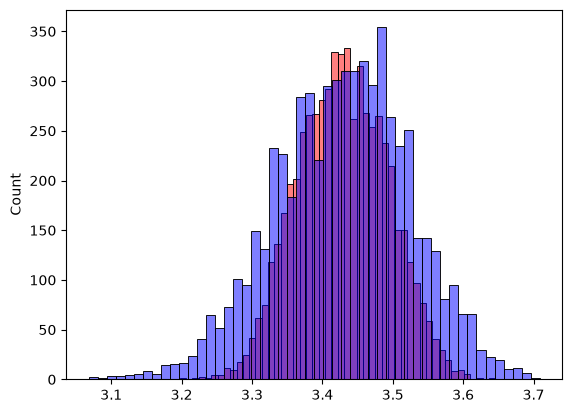

In [41]:
#
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)